$\textbf{SRM Uncertainty Propagation TEST}$

In [ ]:
#DEFINITIONS
import skrf as rf
from skrf.calibration import TRL, TUGMultilineTRL
import numpy as np
import matplotlib.pyplot as plt
from u_srm import uSRM
import metas_unclib as munc
from extract_latex_table import extract_switch_terms, extract_table
munc.use_linprop()

$\textbf{Add Test Data}$

In [18]:

short_p1 = rf.Network('CoaxMeas_data/Short_P1.s1p')['0-40GHz']
short_p2 = rf.Network('CoaxMeas_data/Short_P2.s1p')['0-40GHz']
open_p1 = rf.Network('CoaxMeas_data/Open_P1.s1p')['0-40GHz']
open_p2 = rf.Network('CoaxMeas_data/Open_P2.s1p')['0-40GHz']
load_p1 = rf.Network('CoaxMeas_data/Match_P1.s1p')['0-40GHz']
load_p2 = rf.Network('CoaxMeas_data/Match_P2.s1p')['0-40GHz']
reciprocal = rf.Network('CoaxMeas_data/Network.s2p')['0-40GHz']
recipocal_short_p1= rf.Network('CoaxMeas_data/Network_Short_P1.s1p')['0-40GHz']
recipocal_open_p1= rf.Network('CoaxMeas_data/Network_Open_P1.s1p')['0-40GHz']
recipocal_load_p1= rf.Network('CoaxMeas_data/Network_Match_P1.s1p')['0-40GHz']
FWST,RWST =  extract_switch_terms('Thru_with_switch_terms.tex')
attenuator = rf.Network('CoaxMeas_data/Attenuator.s2p')['0-40GHz']
mismatch_p1 = rf.Network('CoaxMeas_data/Missmatch_P1.s1p')['0-40GHz']
mismatch_p2 = rf.Network('CoaxMeas_data/Missmatch_P2.s1p')['0-40GHz']
attenuator_solr = rf.Network('METAS_SOLR_De_Emb/Attenuator.s2p')['0-40GHz']
freq = short_p1.frequency


$\textbf{Add Ideals}$

In [12]:



reciprocal_est = np.zeros((len(freq),2,2),dtype=complex)
reciprocal_est[0:len(freq),0,0] = 0*np.ones((len(freq)),dtype=complex)
reciprocal_est[0:len(freq),0,1] = np.ones((len(freq)),dtype=complex)
reciprocal_est[0:len(freq),1,0] = np.ones((len(freq)),dtype=complex)
reciprocal_est[0:len(freq),1,1] = 0*np.ones((len(freq)),dtype=complex)
reciprocal_est = rf.Network(frequency=freq,s=reciprocal_est,z0=50)

short_est = -1*np.ones(len(freq))
open_est = 1*np.ones(len(freq))
match_est = 0*np.ones((len(freq)))
match_est = rf.Network('Reference_Standards/Match_F.s1p')['0-40GHz'].s[:,0,0]

match_est_2p = np.zeros((len(freq),2,2),dtype=complex)
match_est_2p[0:len(freq),0,0] = match_est
match_est_2p[0:len(freq),1,1] = match_est
match_est_2p = rf.Network(frequency=freq,s=match_est_2p,z0=50)

short_est_2p = np.zeros((len(freq),2,2),dtype=complex)
short_est_2p[0:len(freq),0,0] = short_est
short_est_2p[0:len(freq),1,1] = short_est
short_est_2p = rf.Network(frequency=freq,s=short_est_2p,z0=50)

open_est_2p = np.zeros((len(freq),2,2),dtype=complex)
open_est_2p[0:len(freq),0,0] = open_est
open_est_2p[0:len(freq),1,1] = open_est
open_est_2p = rf.Network(frequency=freq,s=open_est_2p,z0=50)

$\textbf{Define some dummy standard deviations for quantities}$

In [20]:
noise_data = extract_table("Uncertainty_Contributor_Data/Noise_Floor.tex")
drift_data = extract_table("Uncertainty_Contributor_Data/Drift.tex")
cable_data = extract_table("Uncertainty_Contributor_Data/Cable.tex")
connector_data = extract_table("Uncertainty_Contributor_Data/Connector.tex")
linearity_data = extract_table("Uncertainty_Contributor_Data/Linearity.tex")
open_data = extract_table("Uncertainty_Contributor_Data/Open.tex")
short_data = extract_table("Uncertainty_Contributor_Data/Short.tex")
load_data = extract_table("Uncertainty_Contributor_Data/Match.tex")

NameError: name 'extract_table' is not defined

In [13]:
u_short = 0.1**2
u_open = 0.1**2
u_match = 0.005**2
u_reciprocal = 0.005**2
u_match_def = 0.005**2
u_switch_term = 0.005**2
u_reciprocal_GammaA_short = 0.005**2
u_reciprocal_GammaA_open = 0.005**2
u_reciprocal_GammaA_load = 0.005**2

$\textbf{Perform SRM with Uncertainties}$

In [15]:
'''
calSRM = uSRM(symmetric=[short.s11,short.s22, open.s11, open.s22, load.s11, load.s22],
            est_symmetric=[short_est_2p,  open_est_2p, match_est_2p],
            reciprocal=thru,est_reciprocal=reciprocal_est,
            reciprocal_GammaA = [short.s11, open.s11, load.s11],
            matchA=load.s11, matchB=load.s22,
            matchA_def=match_def.s11, matchB_def=match_def.s11,
            switch_term_fw=FWST.s11, switch_term_bw=RWST.s11,
            usymmetric=[u_short,u_short,u_open,u_open,u_match,u_match],
            ureciprocal=u_reciprocal,
            ureciprocal_GammaA=[u_reciprocal_GammaA_short, u_reciprocal_GammaA_open, u_reciprocal_GammaA_load],
            umatchA_def=u_match_def, umatchB_def=u_match_def,
            umatchA=u_match, umatchB=u_match,
            usw_fw=u_switch_term, usw_bw=u_switch_term)
'''
calSRM = uSRM(symmetric=[short_p1,short_p2, open_p1, open_p2, load_p1, load_p2],
            est_symmetric=[short_est_2p,  open_est_2p, match_est_2p],
            reciprocal=reciprocal,est_reciprocal=reciprocal_est,
            reciprocal_GammaA = [recipocal_short_p1.s11, recipocal_open_p1.s11, recipocal_load_p1.s11],
            matchA=load_p1, matchB=load_p2,
            matchA_def=match_est_2p.s11, matchB_def=match_est_2p.s22,
            switch_term_fw=FWST.s11, switch_term_bw=RWST.s11,
            usymmetric=[u_short,u_short,u_open,u_open,u_match,u_match],
            ureciprocal=u_reciprocal,
            ureciprocal_GammaA=[u_reciprocal_GammaA_short, u_reciprocal_GammaA_open, u_reciprocal_GammaA_load],
            umatchA_def=u_match_def, umatchB_def=u_match_def,
            umatchA=u_match, umatchB=u_match,
            usw_fw=u_switch_term, usw_bw=u_switch_term)

In [16]:
calSRM.u_run()


uSRM is running...


C:\Program Files (x86)\METAS\Metas.UncLib\metas_unclib.py:198: ComplexWarning: Casting complex values to real discards the imaginary part
  c = [_Number(float(bi)) for bi in b.flatten('F')]


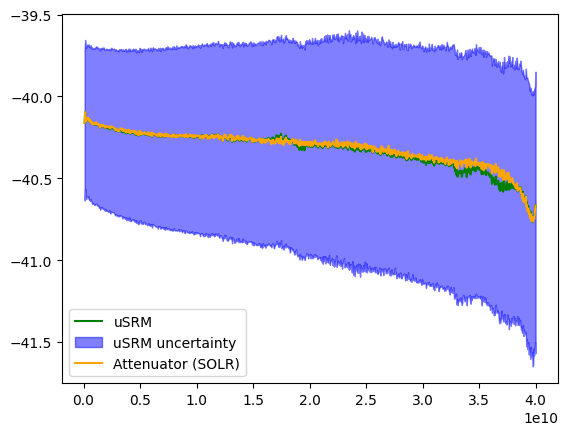

In [19]:
DUT1,unc = calSRM.u_apply_cal(attenuator)

plt.figure()
plt.plot(freq.f, 20*np.log10(np.abs(DUT1.to_dataframe('s')['s 21'])),label='uSRM',color='green')
plt.fill_between(freq.f, (20*np.log10(np.abs(DUT1.to_dataframe('s')['s 21'])-(np.abs(unc[:,1,0])))), (20*np.log10(np.abs(DUT1.to_dataframe('s')['s 21'])+(np.abs(unc[:,1,0])))), color='blue', alpha=0.5, label='uSRM uncertainty')
plt.plot(freq.f, 20*np.log10(np.abs(attenuator_solr.to_dataframe('s')['s 21'])),label='Attenuator (SOLR)',color='orange')
plt.legend()
plt.show()